# 15 · Distance-weighted E/I synapses and boundary conditions
## Goal
Transfer the established E/I synaptic rule from nearest-neighbor periodic lattices to finite-radius and full inverse-square interactions, with open/periodic boundary controls and explicit coefficient normalization. Keep source assignments, initial states, FHN dynamics, release kinetics and time conventions matched.

This notebook is self-contained and writes only to `results/fhn_ei_distance_boundaries/`. Previous notebooks and their result folders are not dependencies. Requires NumPy, SciPy, pandas, Matplotlib and Jupyter. All quantities are dimensionless; distance weights are mathematical choices, not fitted biological synaptic laws.

## Observations from the executed experiment
All 48 labeled conditions completed, representing 44 unique main trajectories; 41 validation checks passed. Six figures and the underlying CSV tables are saved under `results/fhn_ei_distance_boundaries/`.

For the checkerboard with **open boundaries, recipient coefficient budget 0.08, phase seed 11 and observation window 400–1000**, global event-phase order is **0.805 → 0.489 → 0.886** for nearest neighbors, radius-2 inverse-square and full inverse-square coupling respectively. Thus this controlled example does not show monotonic phase order with range. The corresponding local uncancelled current fraction is **1.000 → 0.398 → 0.400**: extending the checkerboard range adds same-type contacts and permits local E/I cancellation. These are finite-window observations with the stated source arrangement and normalization.

Window sensitivity remains material. Under open boundaries and the recipient budget, phase seed 11, the random layout's nearest-neighbor phase order changes from **0.143** in 400–1000 to **0.355** in 1400–2000; full-range order changes from **0.753** to **0.796**. This does not establish converged asymptotic order.

For the selected open/full-range/random trajectory, the maximum sampled state discrepancy between DOP853 and independent Radau over **0–200** is **4.28×10⁻⁹**; tightening DOP853 tolerances over **0–1000** gives **1.24×10⁻⁸**. These selected numerical checks do not certify every trajectory or resolve long-time attractors.


## Setup: preserve neurons and separate geometric questions
$$\dot v_i=v_i-v_i^3/3-w_i+0.5+\sum_jG_{ij}s_j(E_j-v_i),\quad
\dot w_i=0.08(v_i+0.7-0.8w_i),$$
$$\dot s_j=\mathrm{sigmoid}(v_j/0.1)(1-s_j)-0.2s_j,\qquad E_E=3,E_I=-3.$$
Source columns retain their E/I reversal on every outgoing edge. No diffusion, delay, noise or plasticity is added. Gates start at zero and use graded release. Equal **base** strengths correspond to the ratio-one cut of notebook 14; type-specific strength ratios are held fixed here.

The 6×6 coordinates have spacing 1. Open distance is Euclidean. Periodic distance uses the minimum component displacements min(|Δr|,6−|Δr|), likewise for columns. Each distinct node pair is counted once, including half-box distances; there is no sum over periodic images. Self-interaction is excluded.
$$K_{ij}=\mathbf1_{i\ne j}\mathbf1_{d_{ij}\le R}d_{ij}^{-2}.$$
Three kernels: nearest neighbors (R=1), radius 2, and full range (all distinct nodes in this finite box). The exponent is **2 only** in this dynamical study. Other exponents can be added later; notebook 10's diffusion results are not assumed to transfer to synaptic coupling.

| Coefficient convention | Definition | Control |
|---|---|---|
| per_edge | $G=0.02K$ | Nearest-neighbor coefficient stays 0.02; extending range changes input totals |
| row_budget | $G_{ij}=0.08K_{ij}/\sum_jK_{ij}$ | Every nonisolated recipient coefficient sum equals 0.08 |

Zero-total rows receive zero input. Row normalization fixes coefficients, not gates, currents or E/I cancellation. It generally breaks weight symmetry on open grids and makes outgoing total strength position dependent. This convention differs from notebook 13's **network-average** budget: here every recipient total is fixed. Even with equal E/I counts and base gains, source exposure can differ because source positions have unequal total outgoing weight.

Nearest-neighbor periodic per_edge and row_budget are exactly identical because degree is four; the corresponding open-grid cases differ at boundary nodes. Boundary changes alter distances, neighbors and coefficients together in per_edge runs; row_budget removes the recipient-total difference but does not remove geometric effects.

{'python': '3.12.2', 'numpy': '2.2.6', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


,boundary,kernel,mode,undirected_contacts,min_row_coefficient,mean_row_coefficient,max_row_coefficient,maximum_asymmetry
0,open,nearest,per_edge,60,0.040000,0.066667,0.080000,0.000000e+00
1,open,nearest,row_budget,60,0.080000,0.080000,0.080000,1.333333e-02
2,open,p2_R2,per_edge,158,0.060000,0.107778,0.140000,0.000000e+00
3,open,p2_R2,row_budget,158,0.080000,0.080000,0.080000,8.888889e-03
4,open,p2_full,per_edge,630,0.099280,0.156383,0.201709,0.000000e+00
5,open,p2_full,row_budget,630,0.080000,0.080000,0.080000,4.130169e-03
6,periodic,nearest,per_edge,72,0.080000,0.080000,0.080000,0.000000e+00
7,periodic,nearest,row_budget,72,0.080000,0.080000,0.080000,0.000000e+00
8,periodic,p2_R2,per_edge,216,0.140000,0.140000,0.140000,0.000000e+00
9,periodic,p2_R2,row_budget,216,0.080000,0.080000,0.080000,0.000000e+00


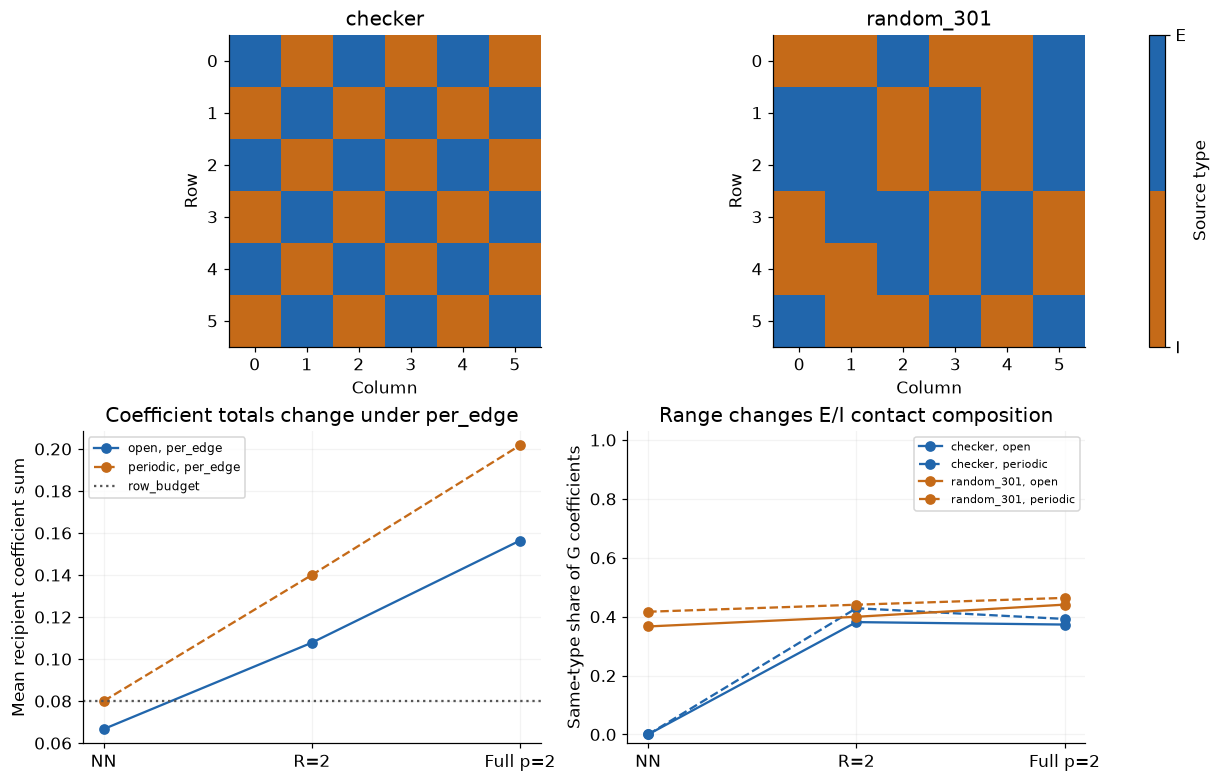

In [2]:
from pathlib import Path
import json,platform
import numpy as np
import pandas as pd
import scipy,matplotlib
from scipy.integrate import solve_ivp
from scipy.special import expit
from scipy.sparse import csr_matrix,lil_matrix
from scipy.sparse.csgraph import connected_components
from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
OUT=Path('results/fhn_ei_distance_boundaries');OUT.mkdir(parents=True,exist_ok=True)
SIDE=6;N=SIDE**2;END=1000.;BURN=400.;DT=.5
A_REC,B_REC,EPS=.7,.8,.08;ALPHA,BETA,WIDTH=1.,.2,.1
PHASE_SEEDS=[11,29];G0=.02;ROW_BUDGET=.08
BOUNDARIES=['open','periodic'];MODES=['per_edge','row_budget']
BLUE,ORANGE,GRAY,OLIVE,PINK='#2166AC','#C56A18','#555555','#8A7515','#A3537B'
plt.rcParams.update({'font.size':11,'figure.dpi':110,'savefig.dpi':160,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
versions=dict(python=platform.python_version(),numpy=np.__version__,scipy=scipy.__version__,pandas=pd.__version__,matplotlib=matplotlib.__version__)
print(versions)
def save(fig,name):
 fig.savefig(OUT/(name+'.png'),bbox_inches='tight');plt.show();plt.close(fig)
def adjacency(side,boundary):
 if side<3 or boundary not in BOUNDARIES:raise ValueError('Invalid grid')
 A=np.zeros((side**2,side**2))
 for r in range(side):
  for c in range(side):
   for dr,dc in [(1,0),(-1,0),(0,1),(0,-1)]:
    rr,cc=r+dr,c+dc
    if boundary=='periodic':rr%=side;cc%=side
    if 0<=rr<side and 0<=cc<side:A[r*side+c,rr*side+cc]=1
 return A
def distance_matrix(side,boundary):
 if side<3 or boundary not in ('open','periodic'): raise ValueError('Invalid grid')
 coords=np.column_stack(np.unravel_index(np.arange(side**2),(side,side))).astype(float)
 delta=np.abs(coords[:,None,:]-coords[None,:,:])
 if boundary=='periodic':delta=np.minimum(delta,side-delta)
 d=np.sqrt(np.sum(delta**2,axis=2))
 off=~np.eye(len(d),dtype=bool)
 if np.any(d[off]<=0):raise ValueError('Distinct nodes must have positive separation')
 return d

def kernel(d,p=2.,radius=np.inf):
 if p<=0 or not np.isfinite(p) or radius<=0 or np.isnan(radius):raise ValueError('Use p>0 and R>0')
 off=~np.eye(len(d),dtype=bool)
 if np.any(d[off]<=0):raise ValueError('Coincident distinct nodes')
 K=np.zeros_like(d);mask=off&(d<=radius+1e-12)
 K[mask]=d[mask]**(-p)
 return K

def normalize(K):
 totals=K.sum(axis=1)
 return np.divide(K,totals[:,None],out=np.zeros_like(K),where=totals[:,None]>0)
PARITY=(np.indices((SIDE,SIDE)).sum(axis=0)%2==0).ravel()
mask=np.ones(N,dtype=bool);mask[np.random.default_rng(301).choice(N,N//2,replace=False)]=False
LAYOUTS={'checker':PARITY.copy(),'random_301':mask}
SPECS={'nearest':1.,'p2_R2':2.,'p2_full':np.inf};KERNEL_NAMES=list(SPECS)
DIST={bc:distance_matrix(SIDE,bc) for bc in BOUNDARIES}
ADJ={bc:adjacency(SIDE,bc) for bc in BOUNDARIES}
KERNELS={(bc,name):kernel(d,p=2.,radius=R) for bc,d in DIST.items() for name,R in SPECS.items()}
def conductance(K,mode):
 if mode=='per_edge':return G0*K
 if mode=='row_budget':return ROW_BUDGET*normalize(K)
 raise ValueError('Unknown coefficient convention')
G_MATRICES={(bc,name,mode):conductance(K,mode) for (bc,name),K in KERNELS.items() for mode in MODES}
assign_rows=[];geometry_rows=[];exposure_rows=[]
for name,mask in LAYOUTS.items():
 for i,isE in enumerate(mask):assign_rows.append(dict(layout=name,node=i,row=i//SIDE,column=i%SIDE,source_type='E' if isE else 'I'))
pd.DataFrame(assign_rows).to_csv(OUT/'source_assignments.csv',index=False)
for (bc,name),K in KERNELS.items():
 pd.DataFrame(K).to_csv(OUT/f'kernel_{bc}_{name}.csv',index=False)
 for mode in MODES:
  G=G_MATRICES[(bc,name,mode)];totals=G.sum(axis=1)
  geometry_rows.append(dict(boundary=bc,kernel=name,mode=mode,undirected_contacts=int(np.count_nonzero(K)/2),
   min_row_coefficient=float(totals.min()),mean_row_coefficient=float(totals.mean()),max_row_coefficient=float(totals.max()),
   maximum_asymmetry=float(np.max(abs(G-G.T)))))
  pd.DataFrame(G).to_csv(OUT/f'conductance_{bc}_{name}_{mode}.csv',index=False)
  for layout,mask in LAYOUTS.items():
   same=G[np.ix_(mask,mask)].sum()+G[np.ix_(~mask,~mask)].sum()
   exposure_rows.append(dict(boundary=bc,kernel=name,mode=mode,layout=layout,same_type_coefficient_fraction=float(same/G.sum()),
    E_source_coefficient_fraction=float(G[:,mask].sum()/G.sum())))
geometry=pd.DataFrame(geometry_rows);geometry.to_csv(OUT/'geometry_and_coefficients.csv',index=False)
exposure=pd.DataFrame(exposure_rows);exposure.to_csv(OUT/'source_coefficient_exposure.csv',index=False)
display(geometry)
fig,axs=plt.subplots(2,2,figsize=(11,7),layout='constrained')
for ax,(name,mask) in zip(axs[0,:],LAYOUTS.items()):
 im=ax.imshow(mask.reshape(SIDE,SIDE),cmap=ListedColormap([ORANGE,BLUE]),vmin=0,vmax=1)
 ax.set(title=name,xlabel='Column',ylabel='Row');ax.grid(False)
fig.colorbar(im,ax=axs[0,:].tolist(),ticks=[0,1],label='Source type').ax.set_yticklabels(['I','E'])
xx=np.arange(3)
for bc,color,style in [('open',BLUE,'-'),('periodic',ORANGE,'--')]:
 part=geometry[(geometry.boundary==bc)&(geometry['mode']=='per_edge')].set_index('kernel').loc[KERNEL_NAMES]
 axs[1,0].plot(xx,part.mean_row_coefficient,'o'+style,color=color,label=f'{bc}, per_edge')
axs[1,0].axhline(ROW_BUDGET,color=GRAY,linestyle=':',label='row_budget')
axs[1,0].set(xticks=xx,xticklabels=['NN','R=2','Full p=2'],ylabel='Mean recipient coefficient sum',title='Coefficient totals change under per_edge');axs[1,0].legend(fontsize=8)
for layout,color in [('checker',BLUE),('random_301',ORANGE)]:
 for bc,style in [('open','-'),('periodic','--')]:
  part=exposure[(exposure.layout==layout)&(exposure.boundary==bc)&(exposure['mode']=='per_edge')].set_index('kernel').loc[KERNEL_NAMES]
  axs[1,1].plot(xx,part.same_type_coefficient_fraction,'o'+style,color=color,label=f'{layout}, {bc}')
axs[1,1].set(xticks=xx,xticklabels=['NN','R=2','Full p=2'],ylabel='Same-type share of G coefficients',title='Range changes E/I contact composition',ylim=(-.03,1.03));axs[1,1].legend(fontsize=7.5)
save(fig,'01_assignments_and_coefficient_audit')

## 1. Inspect actual normalized weights
Show input weights into recipient (0,0) under row_budget. All panels share one scale and each panel sums to 0.08. In the open nearest-neighbor case this corner has two contacts with coefficient 0.04 each; periodic nearest neighbors have four at 0.02 each. Longer-range budgets redistribute weight over more sources. Color indicates conductance coefficients, not input currents or node activity.

R=1 must reproduce independently constructed adjacency matrices on both boundaries. Checkerboard nearest-neighbor contacts are all cross-type. Extending range admits same-type contacts (e.g. diagonals), so the nearest-neighbor checkerboard cancellation argument no longer applies.

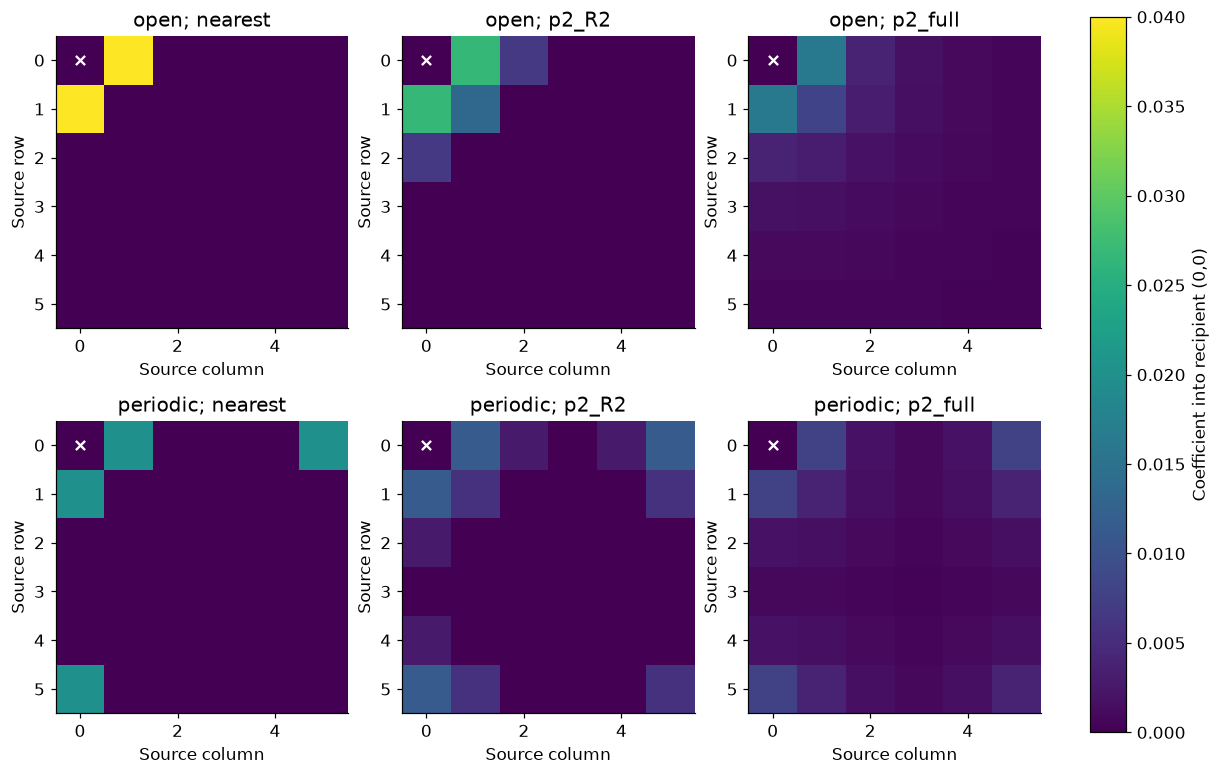

In [4]:
fig,axs=plt.subplots(2,3,figsize=(11,7),layout='constrained')
for row,bc in enumerate(BOUNDARIES):
 for col,name in enumerate(KERNEL_NAMES):
  G=G_MATRICES[(bc,name,'row_budget')]
  im=axs[row,col].imshow(G[0].reshape(SIDE,SIDE),vmin=0,vmax=.04,cmap='viridis')
  axs[row,col].scatter(0,0,color='white',marker='x')
  axs[row,col].set(title=f'{bc}; {name}',xlabel='Source column',ylabel='Source row');axs[row,col].grid(False)
fig.colorbar(im,ax=axs.ravel().tolist(),label='Coefficient into recipient (0,0)')
save(fig,'02_normalized_corner_weights')

## 2. Matched full-network simulations
Two source assignments × two boundaries × three kernels × two coefficient conventions × two phase seeds give 48 labeled conditions. Exactly identical conductance/source/initial-state combinations share a unique run ID; periodic nearest-neighbor normalization is an exact control, not an independent replicate. Other conditions remain distinct.

Keep the previous isolated-cycle initial fields and gates initially zero. End time 1000, discard t<400, sample step 0.5. Only four selected open-row_budget trajectories are retained for diagnostics; other dense trajectories are measured and released. Saved run mappings, node metrics, events and source assignments make the comparisons inspectable.

In [6]:
def inputs(v,s,G,E):return G@(s*E)-v*(G@s)
def rhs_values(y,currents,G,E):
 v,w,s=y.reshape(-1,3).T
 return np.column_stack((v-v**3/3-w+currents+inputs(v,s,G,E),EPS*(v+A_REC-B_REC*w),
  ALPHA*expit(v/WIDTH)*(1-s)-BETA*s)).ravel()
def jacobian(y,G,E):
 n=len(E);v,w,s=y.reshape(n,3).T;q=expit(v/WIDTH);J=lil_matrix((3*n,3*n))
 degree=G@s
 for i in range(n):
  J[3*i,3*i]=1-v[i]**2-degree[i];J[3*i,3*i+1]=-1
  J[3*i+1,3*i]=EPS;J[3*i+1,3*i+1]=-EPS*B_REC
  J[3*i+2,3*i]=ALPHA*q[i]*(1-q[i])*(1-s[i])/WIDTH
  J[3*i+2,3*i+2]=-ALPHA*q[i]-BETA
  for j in G.getrow(i).indices:J[3*i,3*j+2]=G[i,j]*(E[j]-v[i])
 return J.tocsr()
def integrate(initial,G,E,end=END,method='DOP853',rtol=1e-10,atol=1e-12):
 initial=np.asarray(initial,float);G=np.asarray(G,float);E=np.asarray(E,float);n=len(E)
 if initial.shape!=(n,3) or G.shape!=(n,n):raise ValueError('Shape mismatch')
 if not np.isfinite(initial).all() or not np.isfinite(G).all() or not np.isfinite(E).all() or np.any(G<0) or np.any(np.diag(G)!=0):raise ValueError('Invalid state or conductance')
 if np.any(initial[:,2]<0) or np.any(initial[:,2]>1):raise ValueError('Initial gate outside [0,1]')
 Gs=csr_matrix(G);events=[]
 for i in range(n):
  def event(t,y,index=i):return y[3*index]
  event.direction=1;event.terminal=False;events.append(event)
 options={}
 if method in ['Radau','BDF']:options['jac']=lambda t,y:jacobian(y,Gs,E)
 sol=solve_ivp(lambda t,y:rhs_values(y,.5,Gs,E),(0,end),initial.ravel(),method=method,
  rtol=rtol,atol=atol,events=events,dense_output=True,max_step=.25,**options)
 if not sol.success:raise RuntimeError(sol.message)
 return sol
iso=integrate([[2.,-.5,0.]],np.zeros((1,1)),np.array([3.]),end=800.,rtol=1e-10,atol=1e-12)
t0,t1=iso.t_events[0][-2:];PERIOD=t1-t0
INITIAL={};init_rows=[]
for seed in PHASE_SEEDS:
 phases=np.random.default_rng(seed).uniform(0,1,N)
 states=iso.sol(t0+phases*PERIOD).reshape(3,N).T;states[:,2]=0;INITIAL[seed]=states
 for node,(q,z) in enumerate(zip(phases,states)):init_rows.append(dict(phase_seed=seed,node=node,phase_fraction=q,v=z[0],w=z[1],s=z[2]))
pd.DataFrame(init_rows).to_csv(OUT/'initial_states.csv',index=False)
print('Reference isolated period:',PERIOD)

Reference isolated period: 39.474414980238635


## 3. Observables and finite-window scope
Retain node event counts/frequencies/ISI variability, global centered v,w spread, source-population/parity phase order, and local uncancelled input fraction
$$C=\langle|J_i^E+J_i^I|\rangle_{i,t}/\langle|J_i^E|+|J_i^I|\rangle_{i,t}.$$
Currents are separated by source type before averaging; equal coefficients do not imply E/I balance. C is undefined if its denominator is zero.

Event phase interpolates only between actual positive v=0 crossings, without resets or extrapolation. Each group order parameter uses jointly bracketed times for that group; valid-time fractions and absent estimates are retained. Low global R is not a disorder or chaos diagnosis. Source populations are each 18 nodes; group-size/support differences still matter when comparing group and global order. Period frequency/ISI CV require three retained events; count-frequency resolution is 1/600 per node. All time averages use the declared finite grid, not an independently refined temporal quadrature.

In [8]:
def phase_order(phase,mask):
 if not np.any(mask):return np.nan,0.
 valid=np.isfinite(phase[mask]).all(axis=0)
 if not valid.any():return np.nan,0.
 return float(np.abs(np.mean(np.exp(1j*phase[mask][:,valid]),axis=0)).mean()),float(valid.mean())
def measure(sol,mask,G,start=BURN,stop=END):
 times=np.arange(start,stop+DT/10,DT);z=sol.sol(times).reshape(N,3,-1);v,w,s=z[:,0],z[:,1],z[:,2]
 G=csr_matrix(G);E=np.where(mask,3.,-3.)
 JE=inputs(v,s*mask[:,None],G,E[:,None]);JI=inputs(v,s*(~mask)[:,None],G,E[:,None])
 phase=np.full((N,len(times)),np.nan);node_rows=[]
 for i,e in enumerate(sol.t_events):
  recent=e[(e>=start)&(e<=stop)];isi=np.diff(recent)
  if len(e)>=2:
   valid=(times>=e[0])&(times<=e[-1]);phase[i,valid]=np.interp(times[valid],e,2*np.pi*np.arange(len(e)))
  node_rows.append(dict(node=i,source_type='E' if mask[i] else 'I',window_spikes=len(recent),count_frequency=len(recent)/(stop-start),
   period_frequency=float(1/isi.mean()) if len(isi)>=2 else np.nan,isi_cv=float(isi.std()/isi.mean()) if len(isi)>=2 else np.nan,
   mean_E_input=float(JE[i].mean()),mean_I_input=float(JI[i].mean()),rms_E_input=float(np.sqrt(np.mean(JE[i]**2))),rms_I_input=float(np.sqrt(np.mean(JI[i]**2)))))
 nodes=pd.DataFrame(node_rows);centered=z[:,:2]-z[:,:2].mean(axis=0,keepdims=True)
 total=float(np.mean(abs(JE)+abs(JI)));C=float(np.mean(abs(JE+JI))/total) if total>1e-15 else np.nan
 row=dict(state_spread=float(np.sqrt(np.mean(np.sum(centered**2,axis=1)))),mean_count_frequency=float(nodes.count_frequency.mean()),
  std_count_frequency=float(nodes.count_frequency.std(ddof=0)),nodes_with_spikes=int((nodes.window_spikes>0).sum()),
  mean_E_input=float(JE.mean()),mean_I_input=float(JI.mean()),local_uncancelled_fraction=C,
  E_count=int(mask.sum()),I_count=int((~mask).sum()))
 for name,pop in [('all',np.ones(N,dtype=bool)),('E',mask),('I',~mask),('even',PARITY),('odd',~PARITY)]:
  order,coverage=phase_order(phase,pop);row[f'phase_order_{name}']=order;row[f'phase_coverage_{name}']=coverage
  row[f'count_frequency_{name}']=float(nodes.loc[pop,'count_frequency'].mean()) if pop.any() else np.nan
 return row,nodes
cache={};design_rows=[];unique_rows=[];node_tables=[];event_rows=[];bounds=[];SELECTED={}
for bc in BOUNDARIES:
 for name in KERNEL_NAMES:
  for mode in MODES:
   G=G_MATRICES[(bc,name,mode)]
   for layout,mask in LAYOUTS.items():
    E=np.where(mask,3.,-3.)
    for seed in PHASE_SEEDS:
     key=(seed,mask.tobytes(),G.tobytes())
     if key not in cache:
      run_id=f'run_{len(cache)+1:03d}';sol=integrate(INITIAL[seed],G,E)
      stats,nodes=measure(sol,mask,G);unique_rows.append(dict(run_id=run_id,**stats));nodes['run_id']=run_id;node_tables.append(nodes)
      for node,e in enumerate(sol.t_events):event_rows.extend(dict(run_id=run_id,node=node,time=float(t)) for t in e)
      z=sol.sol(np.linspace(0,END,2001)).reshape(N,3,-1)
      bounds.append(dict(run_id=run_id,min_v=float(z[:,0].min()),max_v=float(z[:,0].max()),min_s=float(z[:,2].min()),max_s=float(z[:,2].max())))
      cache[key]=run_id
      if bc=='open' and name in ['nearest','p2_full'] and mode=='row_budget' and seed==11:SELECTED[(layout,name)]=sol
      del sol
     else:run_id=cache[key]
     design_rows.append(dict(boundary=bc,kernel=name,mode=mode,layout=layout,phase_seed=seed,run_id=run_id))
     _=(OUT/'progress.json').write_text(json.dumps(dict(status='running',conditions_processed=len(design_rows),total_conditions=48,unique_runs=len(cache))))
design=pd.DataFrame(design_rows);design.to_csv(OUT/'design_to_run.csv',index=False)
unique=pd.DataFrame(unique_rows);unique.to_csv(OUT/'unique_run_metrics.csv',index=False)
scan=design.merge(unique,on='run_id',validate='many_to_one');scan.to_csv(OUT/'condition_metrics.csv',index=False)
node_metrics=pd.concat(node_tables,ignore_index=True);node_metrics.to_csv(OUT/'node_metrics.csv',index=False)
pd.DataFrame(event_rows).to_csv(OUT/'spike_events.csv',index=False)
bound_table=pd.DataFrame(bounds);bound_table.to_csv(OUT/'sampled_bounds.csv',index=False)
display(scan[(scan.phase_seed==11)&(scan['mode']=='row_budget')][['boundary','kernel','layout','mean_count_frequency','phase_order_all','local_uncancelled_fraction']])
print(len(design),'conditions from',len(unique),'unique simulations.')

,boundary,kernel,layout,mean_count_frequency,phase_order_all,local_uncancelled_fraction
4,open,nearest,checker,0.028102,0.805073,1.000000
6,open,nearest,random_301,0.025833,0.142992,0.549667
12,open,p2_R2,checker,0.026852,0.488603,0.398284
14,open,p2_R2,random_301,0.026389,0.332042,0.417774
20,open,p2_full,checker,0.026620,0.886096,0.400363
22,open,p2_full,random_301,0.025648,0.753154,0.402170
28,periodic,nearest,checker,0.027778,0.660284,1.000000
30,periodic,nearest,random_301,0.026204,0.279719,0.505224
36,periodic,p2_R2,checker,0.026667,0.892767,0.396397
38,periodic,p2_R2,random_301,0.026065,0.606229,0.409265


48 conditions from 44 unique simulations.


## 4. Compare the checkerboard across boundaries and range
Blue versus orange separates coefficient conventions; solid circles versus dashed squares separate phase seeds. Kernels are ordered by range, not continued as a bifurcation branch. Common scales across boundaries support direct comparisons. Each curve contains one initial realization; duplicate periodic-NN curves coincide by construction and do not add replication.

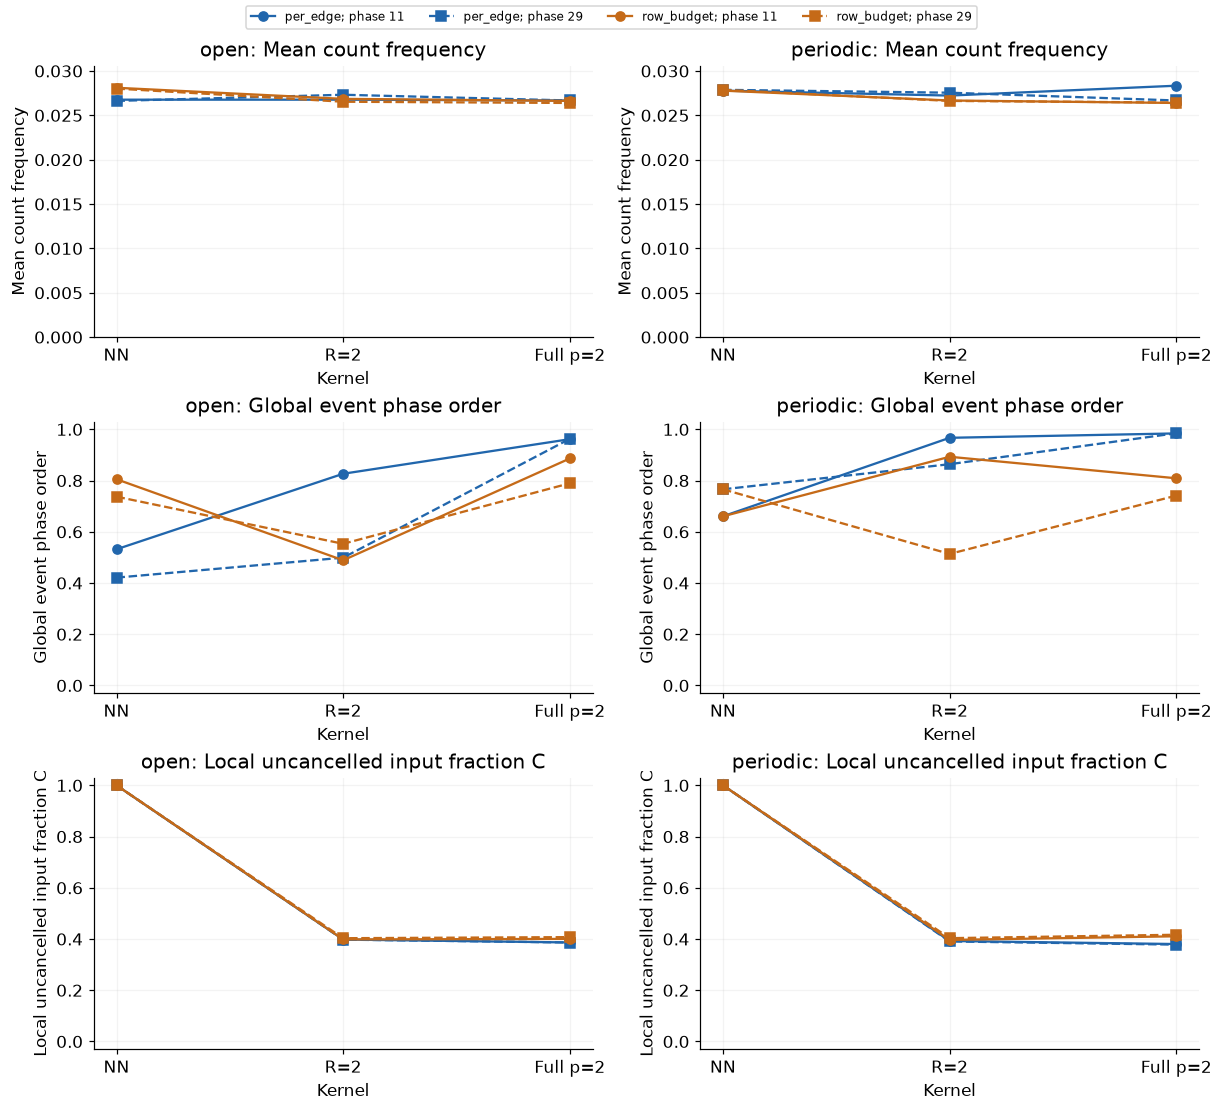

In [10]:
LAYOUT='checker';FIGURE='03_checkerboard_comparison'
fig,axs=plt.subplots(3,2,figsize=(11,10),layout='constrained');xx=np.arange(3)
metrics=[('mean_count_frequency','Mean count frequency'),('phase_order_all','Global event phase order'),('local_uncancelled_fraction','Local uncancelled input fraction C')]
for col,bc in enumerate(BOUNDARIES):
 for mode,color in [('per_edge',BLUE),('row_budget',ORANGE)]:
  for seed,style,marker in [(11,'-','o'),(29,'--','s')]:
   part=scan[(scan.layout==LAYOUT)&(scan.boundary==bc)&(scan['mode']==mode)&(scan.phase_seed==seed)].set_index('kernel').loc[KERNEL_NAMES]
   for row,(metric,label) in enumerate(metrics):axs[row,col].plot(xx,part[metric],linestyle=style,marker=marker,color=color,label=f'{mode}; phase {seed}')
 for row,(metric,label) in enumerate(metrics):
  axs[row,col].set(title=f'{bc}: {label}',ylabel=label,xticks=xx,xticklabels=['NN','R=2','Full p=2'],xlabel='Kernel')
  axs[row,col].set_ylim(0,scan.mean_count_frequency.max()*1.08) if row==0 else axs[row,col].set_ylim(-.03,1.03)
fig.legend(*axs[0,0].get_legend_handles_labels(),loc='outside upper center',ncol=4,fontsize=8)
save(fig,FIGURE)


## 5. Repeat the same controls for the matched random assignment
The source positions and initial fields remain identical across boundaries, kernels and conventions. This tests one specific random source pattern, not a random-graph or source-assignment ensemble. A boundary or range effect in this small experiment is not a universal topology ranking.

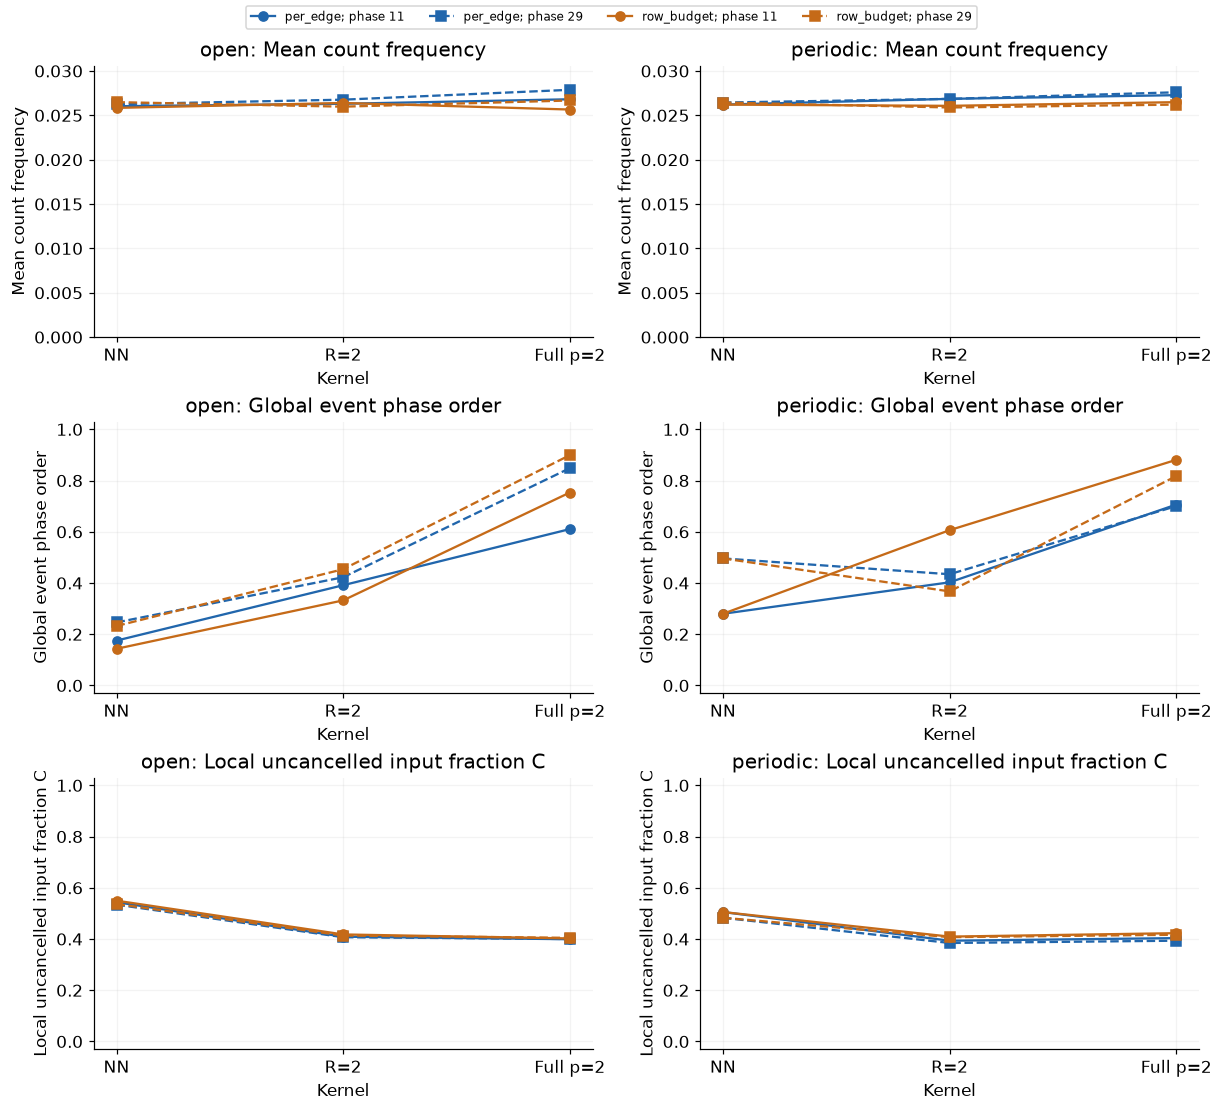

In [12]:
LAYOUT='random_301';FIGURE='04_random_assignment_comparison'
fig,axs=plt.subplots(3,2,figsize=(11,10),layout='constrained');xx=np.arange(3)
metrics=[('mean_count_frequency','Mean count frequency'),('phase_order_all','Global event phase order'),('local_uncancelled_fraction','Local uncancelled input fraction C')]
for col,bc in enumerate(BOUNDARIES):
 for mode,color in [('per_edge',BLUE),('row_budget',ORANGE)]:
  for seed,style,marker in [(11,'-','o'),(29,'--','s')]:
   part=scan[(scan.layout==LAYOUT)&(scan.boundary==bc)&(scan['mode']==mode)&(scan.phase_seed==seed)].set_index('kernel').loc[KERNEL_NAMES]
   for row,(metric,label) in enumerate(metrics):axs[row,col].plot(xx,part[metric],linestyle=style,marker=marker,color=color,label=f'{mode}; phase {seed}')
 for row,(metric,label) in enumerate(metrics):
  axs[row,col].set(title=f'{bc}: {label}',ylabel=label,xticks=xx,xticklabels=['NN','R=2','Full p=2'],xlabel='Kernel')
  axs[row,col].set_ylim(0,scan.mean_count_frequency.max()*1.08) if row==0 else axs[row,col].set_ylim(-.03,1.03)
fig.legend(*axs[0,0].get_legend_handles_labels(),loc='outside upper center',ncol=4,fontsize=8)
save(fig,FIGURE)


## 6. Inspect spatial states and rasters under the fixed recipient budget
Show open boundaries, row_budget and phase seed 11. Columns compare nearest neighbors with full inverse-square coupling; source locations and initial states are unchanged. Activation snapshots at t=980 share one scale. Raster rows are ordered E sources then I sources, not by spatial node index. Range changes both geometry and source-type exposure; normalized coefficient totals do not fix actual currents or phase organization. No wave/spiral classification is inferred from these snapshots.

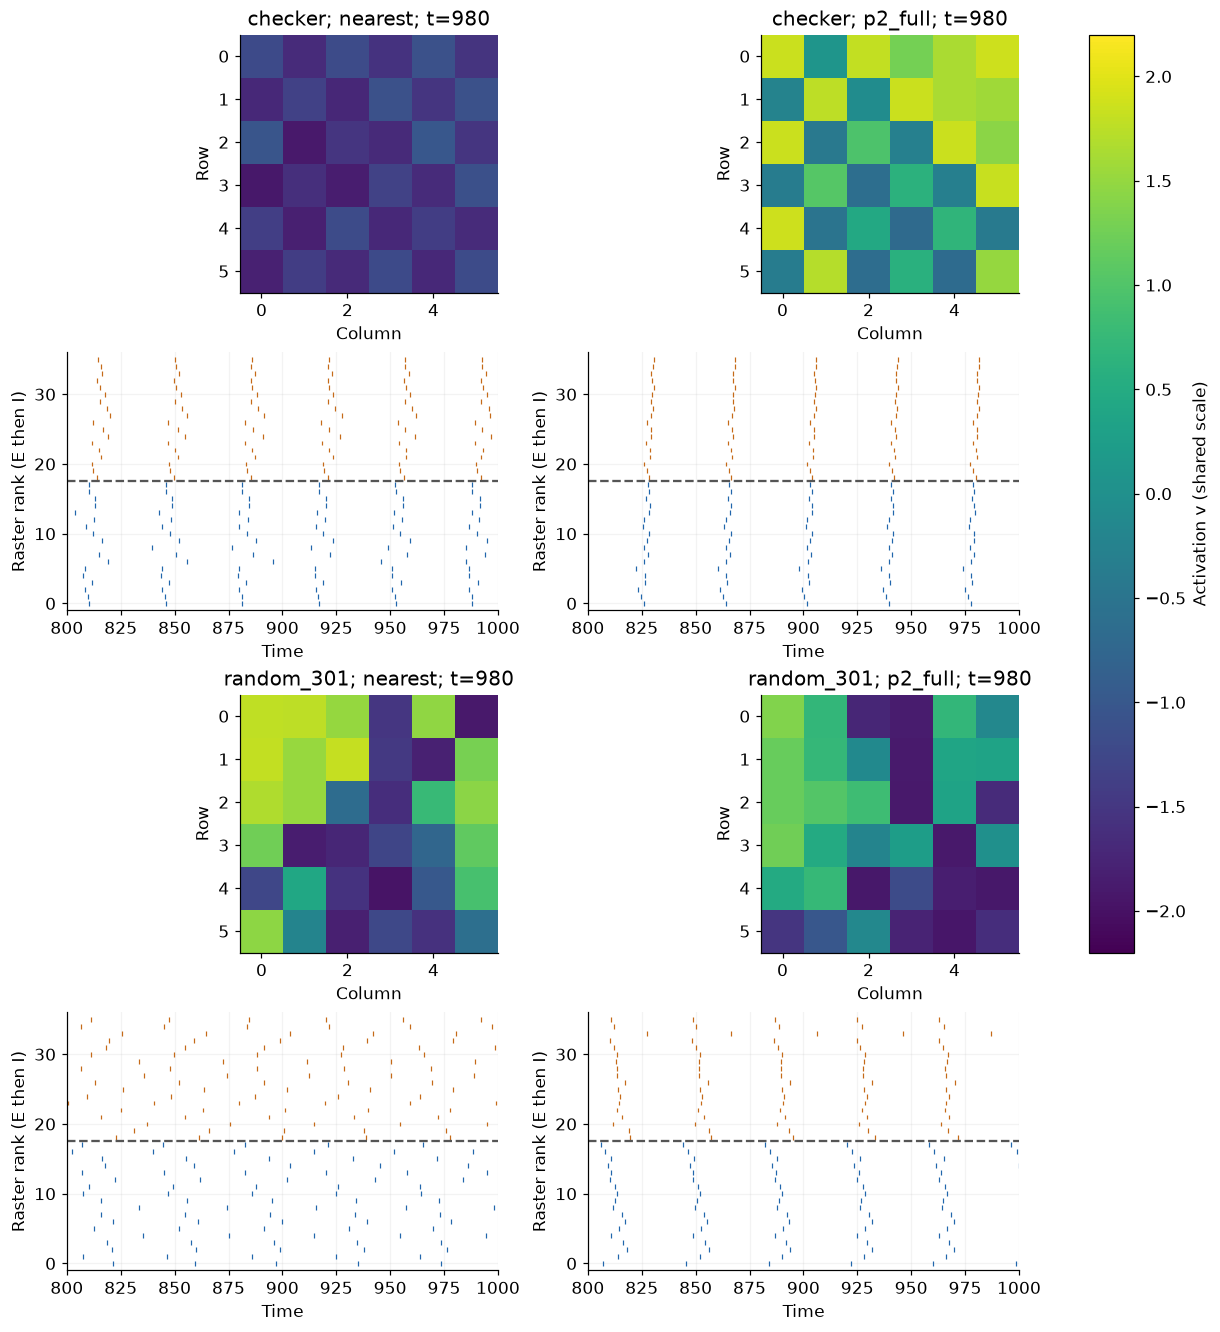

In [14]:
fig,axs=plt.subplots(4,2,figsize=(11,12),layout='constrained')
for group,layout in enumerate(['checker','random_301']):
 mask=LAYOUTS[layout];order=np.r_[np.flatnonzero(mask),np.flatnonzero(~mask)]
 for col,name in enumerate(['nearest','p2_full']):
  sol=SELECTED[(layout,name)]
  im=axs[2*group,col].imshow(sol.sol(980.).reshape(N,3)[:,0].reshape(SIDE,SIDE),vmin=-2.2,vmax=2.2,cmap='viridis')
  axs[2*group,col].set(title=f'{layout}; {name}; t=980',xlabel='Column',ylabel='Row');axs[2*group,col].grid(False)
  for rank,node in enumerate(order):
   e=sol.t_events[node];e=e[(e>=800)&(e<=1000)]
   axs[2*group+1,col].vlines(e,rank-.35,rank+.35,color=BLUE if mask[node] else ORANGE,linewidth=.8)
  axs[2*group+1,col].axhline(17.5,color=GRAY,linestyle='--');axs[2*group+1,col].set(xlabel='Time',ylabel='Raster rank (E then I)',xlim=(800,1000),ylim=(-1,N))
fig.colorbar(im,ax=axs[[0,2],:].ravel().tolist(),label='Activation v (shared scale)')
save(fig,'05_open_budget_snapshots_and_rasters')

## 7. Validate distance, coefficient and synaptic contracts
Check open/periodic minimum-image distances, no self-input, exact nearest-neighbor recovery, row budgets, source-column reversals and the periodic-NN duplicate control. Raw K is symmetric; normalized open G need not be. No conservation law or diffusive synchronization bound is transferred to synaptic input.

For the open/full-inverse-square/row_budget/random_301/phase-11 case, compare independent DOP853/Radau over 0–200 and tighter DOP853 over 0–1000. Extend the four selected open-row_budget cases to time 2000 for window comparisons. These are selected numerical audits, not universal late-time certificates or proof of stationarity.

,check,error,limit,passed
0,open: symmetric distance,0.000000e+00,1.000000e-12,True
1,open: radius-one equals NN adjacency,0.000000e+00,1.000000e-12,True
2,"open, nearest: no self input",0.000000e+00,1.000000e-12,True
3,"open, nearest: raw symmetry",0.000000e+00,1.000000e-12,True
4,"open, nearest: recipient budget",1.387779e-17,1.000000e-12,True
5,"open, p2_R2: no self input",0.000000e+00,1.000000e-12,True
6,"open, p2_R2: raw symmetry",0.000000e+00,1.000000e-12,True
7,"open, p2_R2: recipient budget",1.387779e-17,1.000000e-12,True
8,"open, p2_full: no self input",0.000000e+00,1.000000e-12,True
9,"open, p2_full: raw symmetry",0.000000e+00,1.000000e-12,True


,layout,kernel,window,mean_count_frequency,phase_order_all,local_uncancelled_fraction
0,checker,nearest,400–1000,0.028102,0.805073,1.000000
1,checker,nearest,1400–2000,0.028148,0.859879,1.000000
2,checker,p2_full,400–1000,0.026620,0.886096,0.400363
3,checker,p2_full,1400–2000,0.025509,0.960171,0.398111
4,random_301,nearest,400–1000,0.025833,0.142992,0.549667
5,random_301,nearest,1400–2000,0.026296,0.354847,0.534097
6,random_301,p2_full,400–1000,0.025648,0.753154,0.402170
7,random_301,p2_full,1400–2000,0.026574,0.796132,0.415569


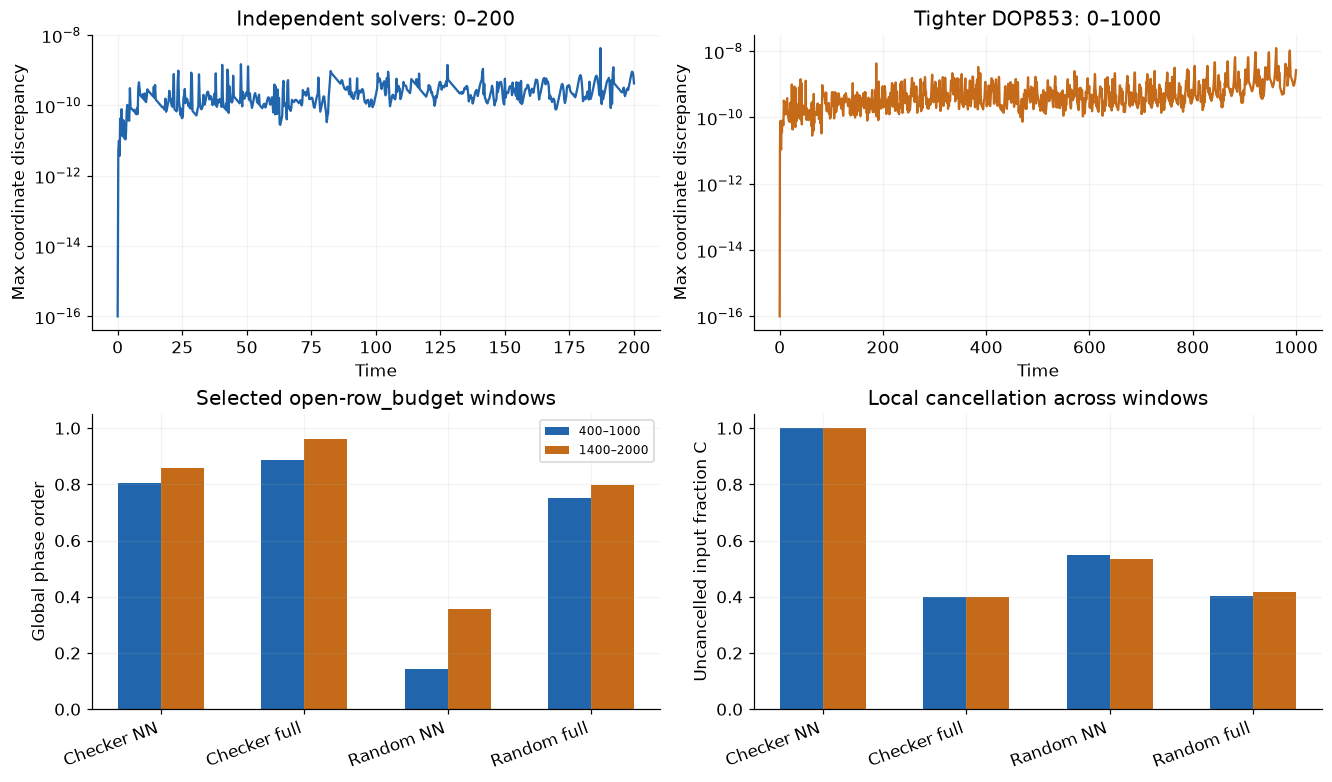

Completed 48 conditions from 44 unique runs; 41 checks passed.


In [16]:
checks=[]
def check(name,error,limit):checks.append(dict(check=name,error=float(error),limit=limit,passed=bool(error<limit)))
for bc,d in DIST.items():
 check(f'{bc}: symmetric distance',np.max(abs(d-d.T)),1e-12)
 check(f'{bc}: radius-one equals NN adjacency',np.max(abs(kernel(d,p=2,radius=1)-ADJ[bc])),1e-12)
 for name in KERNEL_NAMES:
  K=KERNELS[(bc,name)];G=G_MATRICES[(bc,name,'row_budget')]
  check(f'{bc}, {name}: no self input',np.max(abs(np.diag(K))),1e-12)
  check(f'{bc}, {name}: raw symmetry',np.max(abs(K-K.T)),1e-12)
  check(f'{bc}, {name}: recipient budget',np.max(abs(G.sum(axis=1)-ROW_BUDGET)),1e-12)
check('Open opposite corners distance',abs(DIST['open'][0,-1]-np.sqrt(50)),1e-12)
check('Periodic opposite corners distance',abs(DIST['periodic'][0,-1]-np.sqrt(2)),1e-12)
check('Inverse square at a diagonal neighbor',abs(KERNELS[('open','p2_full')][0,SIDE+1]-.5),1e-12)
check('Zero rows normalize to zero',np.max(abs(normalize(np.zeros((2,2))))),1e-12)
for name,mask in LAYOUTS.items():check(f'{name}: 18 E sources',abs(mask.sum()-18),.5)
check('Periodic NN coefficient identity',np.max(abs(G_MATRICES[('periodic','nearest','per_edge')]-G_MATRICES[('periodic','nearest','row_budget')])),1e-12)
pair=design[(design.boundary=='periodic')&(design.kernel=='nearest')].pivot(index=['layout','phase_seed'],columns='mode',values='run_id')
check('Periodic NN exact duplicate IDs',int((pair.per_edge!=pair.row_budget).sum()),.5)
check('One unique result per ID',len(unique)-unique.run_id.nunique(),.5)
check('All design conditions have results',scan.run_id.isna().sum()+len(design)-len(scan),.5)
check('Sampled gates in [0,1]',max(0.,-bound_table.min_s.min(),bound_table.max_s.max()-1),1e-8)
check('Sampled activation within reversals',max(0.,-3.-bound_table.min_v.min(),bound_table.max_v.max()-3.),1e-8)
check('Mean E current nonnegative',max(0.,-unique.mean_E_input.min()),1e-10)
check('Mean I current nonpositive',max(0.,unique.mean_I_input.max()),1e-10)
nearest_checker=scan[(scan.layout=='checker')&(scan.kernel=='nearest')].local_uncancelled_fraction
check('Nearest-neighbor checker has no local E/I cancellation',np.max(abs(nearest_checker-1)),1e-10)
mask=LAYOUTS['random_301'];G=G_MATRICES[('open','p2_full','row_budget')];E=np.where(mask,3.,-3.)
selected=SELECTED[('random_301','p2_full')]
short_times=np.linspace(0,200,801);reference=integrate(INITIAL[11],G,E,end=200.,method='Radau',rtol=2e-11,atol=2e-13)
independent_error=float(np.max(abs(selected.sol(short_times)-reference.sol(short_times))))
check('Independent solvers on 0–200',independent_error,2e-4)
independent_event_error=0.
for e,er in zip(selected.t_events,reference.t_events):
 e=e[e<=200];assert len(e)==len(er)
 if len(e):independent_event_error=max(independent_event_error,float(np.max(abs(e-er))))
check('Independent events on 0–200',independent_event_error,2e-4)
test_times=np.linspace(0,END,2001);tighter=integrate(INITIAL[11],G,E,rtol=1e-12,atol=1e-14)
tight_error=float(np.max(abs(selected.sol(test_times)-tighter.sol(test_times))))
check('Full-window tighter state integration',tight_error,2e-3)
tight_event_error=0.
for e,er in zip(selected.t_events,tighter.t_events):
 assert len(e)==len(er)
 if len(e):tight_event_error=max(tight_event_error,float(np.max(abs(e-er))))
check('Full-window tighter event times',tight_event_error,2e-3)
validation=pd.DataFrame(checks);validation.to_csv(OUT/'validation_checks.csv',index=False);display(validation)
assert validation.passed.all()
window_rows=[]
for layout,mask in LAYOUTS.items():
 E=np.where(mask,3.,-3.)
 for name in ['nearest','p2_full']:
  G=G_MATRICES[('open',name,'row_budget')];long=integrate(INITIAL[11],G,E,end=2000.)
  early,_=measure(SELECTED[(layout,name)],mask,G);later,_=measure(long,mask,G,1400.,2000.)
  window_rows.extend([dict(layout=layout,kernel=name,window='400–1000',**early),dict(layout=layout,kernel=name,window='1400–2000',**later)])
windows=pd.DataFrame(window_rows);windows.to_csv(OUT/'window_sensitivity.csv',index=False)
display(windows[['layout','kernel','window','mean_count_frequency','phase_order_all','local_uncancelled_fraction']])
fig,axs=plt.subplots(2,2,figsize=(12,7),layout='constrained')
axs[0,0].semilogy(short_times,np.maximum(np.max(abs(selected.sol(short_times)-reference.sol(short_times)),axis=0),1e-16),color=BLUE)
axs[0,0].set(xlabel='Time',ylabel='Max coordinate discrepancy',title='Independent solvers: 0–200')
axs[0,1].semilogy(test_times,np.maximum(np.max(abs(selected.sol(test_times)-tighter.sol(test_times)),axis=0),1e-16),color=ORANGE)
axs[0,1].set(xlabel='Time',ylabel='Max coordinate discrepancy',title='Tighter DOP853: 0–1000')
keys=[('checker','nearest'),('checker','p2_full'),('random_301','nearest'),('random_301','p2_full')];xx=np.arange(4)
for window,color,offset in [('400–1000',BLUE,-.15),('1400–2000',ORANGE,.15)]:
 p=windows[windows.window==window].set_index(['layout','kernel']).loc[keys]
 axs[1,0].bar(xx+offset,p.phase_order_all,width=.3,color=color,label=window)
 axs[1,1].bar(xx+offset,p.local_uncancelled_fraction,width=.3,color=color)
for ax in axs[1,:]:
 ax.set_xticks(xx,['Checker NN','Checker full','Random NN','Random full'],rotation=20,ha='right');ax.set_ylim(0,1.05)
axs[1,0].set(ylabel='Global phase order',title='Selected open-row_budget windows');axs[1,0].legend(fontsize=8)
axs[1,1].set(ylabel='Uncancelled input fraction C',title='Local cancellation across windows')
save(fig,'06_numerical_and_window_checks')
summary=dict(versions=versions,side=SIDE,nodes=N,boundaries=BOUNDARIES,layouts=list(LAYOUTS),source_fraction_I=.5,
 kernels={k:dict(p=2,radius=None if np.isinf(v) else v) for k,v in SPECS.items()},modes=MODES,g0=G0,recipient_budget=ROW_BUDGET,
 parameters=dict(a=A_REC,b=B_REC,epsilon=EPS,current=.5,alpha=ALPHA,beta=BETA,release_width=WIDTH,E_E=3,E_I=-3),
 phase_seeds=PHASE_SEEDS,duration=END,burn=BURN,sampling_step=DT,solver=dict(method='DOP853',rtol=1e-10,atol=1e-12,max_step=.25),
 design_conditions=len(design),unique_dynamical_runs=len(unique),checks_passed=int(validation.passed.sum()),
 independent_solver_horizon=200.,independent_state_error=independent_error,independent_event_error=independent_event_error,
 tighter_full_state_error=tight_error,tighter_full_event_error=tight_event_error,sampled_v_range=[float(bound_table.min_v.min()),float(bound_table.max_v.max())])
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
_=(OUT/'progress.json').write_text(json.dumps(dict(status='complete',conditions_processed=len(design),total_conditions=len(design),unique_runs=len(unique))))
print('Completed',len(design),'conditions from',len(unique),'unique runs;',len(checks),'checks passed.')

## Next extension and limitations
Proceed to graph-family comparisons only after defining controlled graph size, degree/weight budget, source assignments and meaningful geometry. Distance has an explicit spatial meaning here; shortest-path distance on an abstract graph is a separate model choice. Later experiments can vary inverse-distance exponent, unequal E/I strengths, larger grids, source layouts and more initial realizations independently.

This study uses two specific half/half layouts, one graph size, exponent 2, three ranges, two boundaries and two phase seeds. Per-edge range changes also change total coefficient strength; row_budget controls recipient totals but changes outgoing source exposure and generally weight symmetry on open grids. Neither convention fixes currents or establishes physiological balance. Full range means a finite box, not an infinite-lattice or thermodynamic limit. Periodic geometry uses one minimum image per distinct source, not all periodic replicas. The measured activity/phase differences are finite-window observations, not a bifurcation diagram, stable-attractor classification, wave speed, disorder diagnosis, chaos result or universal boundary/range ranking.

Dynamics and observations follow notebooks 11–14; distance conventions follow notebook 10, with synaptic rather than diffusive input here. [Neuronal Dynamics §3.1](https://neuronaldynamics.epfl.ch/online/Ch3.S1.html) supplies reversal-current/first-order gate background, not the chosen distance law or parameters. [SciPy solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html) documents integration and event handling. No calibrated physiological units, noise, delays or plasticity are introduced. Numerical accuracy checks cover selected trajectories/horizons; finite sampling and limited replication remain. Logarithmic discrepancy plots use a display floor of 10⁻¹⁶.